## <a id='toc1_1_'></a>[***Importing Libraries***](#toc0_)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

### <a id='toc1_1_1_'></a>[***Ignoring random library and suggestion warnings***](#toc0_)

In [2]:
import warnings
warnings.filterwarnings("ignore")

---

## <a id='toc1_2_'></a>[***Loading the Dataset***](#toc0_)

In [3]:
df = pd.read_csv("waterQualityPrediction.csv")

---

## <a id='toc1_3_'></a>[***Basic Understanding of Dataset***](#toc0_)

In [4]:
df.shape

(7999, 21)

In [5]:
df.head(10)

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1
5,0.94,14.47,0.03,2.88,0.003,0.80,0.43,1.38,0.11,0.67,...,0.135,9.75,1.89,0.006,27.17,5.42,0.08,0.19,0.02,1
6,2.36,5.6,0.01,1.35,0.004,1.28,0.62,1.88,0.33,0.13,...,0.021,18.60,1.78,0.007,45.34,2.84,0.10,0.24,0.08,0
7,3.93,19.87,0.04,0.66,0.001,6.22,0.10,1.86,0.86,0.16,...,0.197,13.65,1.81,0.001,53.35,7.24,0.08,0.08,0.07,0
8,0.60,24.58,0.01,0.71,0.005,3.14,0.77,1.45,0.98,0.35,...,0.167,14.66,1.84,0.004,23.43,4.99,0.08,0.25,0.08,1
9,0.22,16.76,0.02,1.37,0.007,6.40,0.49,0.82,1.24,0.83,...,0.109,4.79,1.46,0.010,30.42,0.08,0.03,0.31,0.01,1


In [6]:
df.tail(10)

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
7989,0.01,27.73,0.06,0.77,0.09,0.20,0.03,0.00,0.58,0.0,...,0.112,11.74,1.0,0.007,7.58,7.21,0.07,0.04,0.09,0
7990,0.00,3.11,0.07,1.24,0.07,0.06,0.03,0.04,0.74,0.0,...,0.016,15.15,1.0,0.005,0.46,6.24,0.03,0.09,0.05,0
7991,0.03,8.94,0.02,1.25,0.08,0.22,0.02,0.05,0.71,0.0,...,0.112,11.97,1.0,0.001,7.18,1.73,0.00,0.04,0.06,1
7992,0.04,10.84,0.06,0.49,0.04,0.08,0.03,0.08,0.49,0.0,...,0.151,14.44,1.0,0.003,0.34,2.16,0.06,0.03,0.05,1
7993,0.02,5.24,0.05,0.77,0.02,0.57,0.04,0.03,0.15,0.0,...,0.085,19.41,1.0,0.001,1.68,3.55,0.05,0.07,0.07,1
7994,0.05,7.78,0.00,1.95,0.04,0.10,0.03,0.03,1.37,0.0,...,0.197,14.29,1.0,0.005,3.57,2.13,0.09,0.06,0.03,1
7995,0.05,24.22,0.02,0.59,0.01,0.45,0.02,0.02,1.48,0.0,...,0.031,10.27,1.0,0.001,1.48,1.11,0.09,0.10,0.08,1
7996,0.09,6.85,0.00,0.61,0.03,0.05,0.05,0.02,0.91,0.0,...,0.182,15.92,1.0,0.000,1.35,4.84,0.00,0.04,0.05,1
7997,0.01,10,0.01,2.00,0.00,2.00,0.00,0.09,0.00,0.0,...,0.000,0.00,0.0,0.000,0.00,0.00,0.00,0.00,0.00,1
7998,0.04,6.85,0.01,0.70,0.03,0.05,0.01,0.03,1.00,0.0,...,0.182,15.92,1.0,0.000,1.35,4.84,0.00,0.04,0.05,1


In [7]:
df.columns

Index(['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine',
       'chromium', 'copper', 'flouride', 'bacteria', 'viruses', 'lead',
       'nitrates', 'nitrites', 'mercury', 'perchlorate', 'radium', 'selenium',
       'silver', 'uranium', 'is_safe'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7999 entries, 0 to 7998
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   aluminium    7999 non-null   float64
 1   ammonia      7999 non-null   object 
 2   arsenic      7999 non-null   float64
 3   barium       7999 non-null   float64
 4   cadmium      7999 non-null   float64
 5   chloramine   7999 non-null   float64
 6   chromium     7999 non-null   float64
 7   copper       7999 non-null   float64
 8   flouride     7999 non-null   float64
 9   bacteria     7999 non-null   float64
 10  viruses      7999 non-null   float64
 11  lead         7999 non-null   float64
 12  nitrates     7999 non-null   float64
 13  nitrites     7999 non-null   float64
 14  mercury      7999 non-null   float64
 15  perchlorate  7999 non-null   float64
 16  radium       7999 non-null   float64
 17  selenium     7999 non-null   float64
 18  silver       7999 non-null   float64
 19  uraniu

### <a id='toc1_3_1_'></a>[***Observations:***](#toc0_)
- We can observe that ammonia and is_safe are having different data types...
- Lets transform them into appropriate data types using ***astype()*** method

---
---

## <a id='toc1_4_'></a>[***Data Transformation***](#toc0_)

---

In [9]:
df = df[df['ammonia'] != '#NUM!']

In [10]:
df['ammonia'] = df['ammonia'].astype('float')
df['is_safe'] = df['is_safe'].astype('int')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7996 entries, 0 to 7998
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   aluminium    7996 non-null   float64
 1   ammonia      7996 non-null   float64
 2   arsenic      7996 non-null   float64
 3   barium       7996 non-null   float64
 4   cadmium      7996 non-null   float64
 5   chloramine   7996 non-null   float64
 6   chromium     7996 non-null   float64
 7   copper       7996 non-null   float64
 8   flouride     7996 non-null   float64
 9   bacteria     7996 non-null   float64
 10  viruses      7996 non-null   float64
 11  lead         7996 non-null   float64
 12  nitrates     7996 non-null   float64
 13  nitrites     7996 non-null   float64
 14  mercury      7996 non-null   float64
 15  perchlorate  7996 non-null   float64
 16  radium       7996 non-null   float64
 17  selenium     7996 non-null   float64
 18  silver       7996 non-null   float64
 19  uranium    

In [11]:
df.rename(columns={'is_safe': 'potability'}, inplace=True)

In [12]:
df

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,potability
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7994,0.05,7.78,0.00,1.95,0.040,0.10,0.03,0.03,1.37,0.00,...,0.197,14.29,1.00,0.005,3.57,2.13,0.09,0.06,0.03,1
7995,0.05,24.22,0.02,0.59,0.010,0.45,0.02,0.02,1.48,0.00,...,0.031,10.27,1.00,0.001,1.48,1.11,0.09,0.10,0.08,1
7996,0.09,6.85,0.00,0.61,0.030,0.05,0.05,0.02,0.91,0.00,...,0.182,15.92,1.00,0.000,1.35,4.84,0.00,0.04,0.05,1
7997,0.01,10.00,0.01,2.00,0.000,2.00,0.00,0.09,0.00,0.00,...,0.000,0.00,0.00,0.000,0.00,0.00,0.00,0.00,0.00,1


In [13]:
df.describe()

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,potability
count,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,...,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000,7996.000000
mean,0.666396,14.278212,0.161477,1.567928,0.042803,2.177589,0.247300,0.805940,0.771646,0.319714,...,0.099431,9.819250,1.329846,0.005193,16.465266,2.920106,0.049684,0.147811,0.044672,0.114057
std,1.265323,8.878930,0.252632,1.216227,0.036049,2.567210,0.270663,0.653595,0.435423,0.329497,...,0.058169,5.541977,0.573271,0.002967,17.688827,2.322805,0.028773,0.143569,0.026906,0.317900
min,0.000000,-0.080000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.040000,6.577500,0.030000,0.560000,0.008000,0.100000,0.050000,0.090000,0.407500,0.000000,...,0.048000,5.000000,1.000000,0.003000,2.170000,0.820000,0.020000,0.040000,0.020000,0.000000
50%,0.070000,14.130000,0.050000,1.190000,0.040000,0.530000,0.090000,0.750000,0.770000,0.220000,...,0.102000,9.930000,1.420000,0.005000,7.745000,2.410000,0.050000,0.080000,0.050000,0.000000
75%,0.280000,22.132500,0.100000,2.482500,0.070000,4.240000,0.440000,1.390000,1.160000,0.610000,...,0.151000,14.610000,1.760000,0.008000,29.487500,4.670000,0.070000,0.240000,0.070000,0.000000
max,5.050000,29.840000,1.050000,4.940000,0.130000,8.680000,0.900000,2.000000,1.500000,1.000000,...,0.200000,19.830000,2.930000,0.010000,60.010000,7.990000,0.100000,0.500000,0.090000,1.000000


---
---

## <a id='toc1_5_'></a>[***Checking NULL values***](#toc0_)

In [14]:
df.isnull().sum()

,0
aluminium,0
ammonia,0
arsenic,0
barium,0
cadmium,0
chloramine,0
chromium,0
copper,0
flouride,0
bacteria,0


### <a id='toc1_5_1_'></a>[***Observations:***](#toc0_)
- *There are no null values in this dataset*

---

#### <a id='toc1_5_1_1_'></a>[***Lets represent the null values in visualization form... lets be clear with in a glance***](#toc0_)

<Axes: >

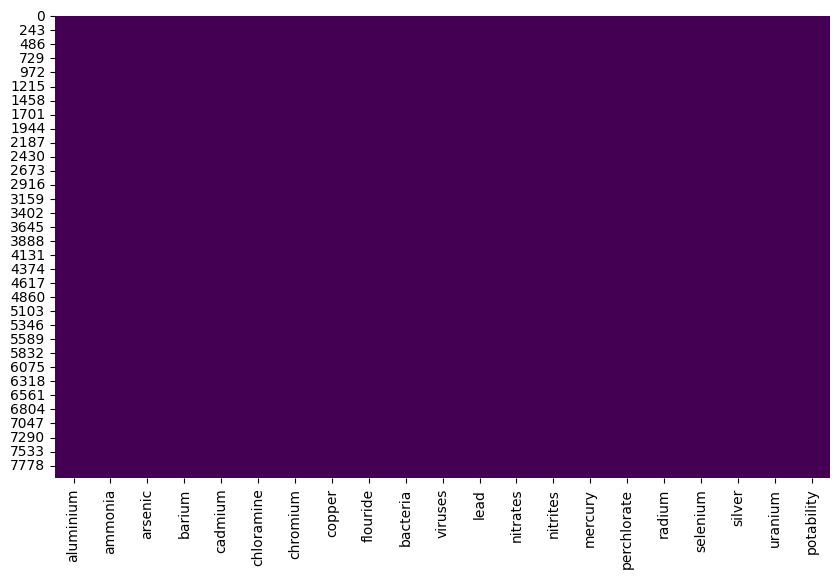

In [125]:
plt.figure(figsize = (10,6))
sns.heatmap(df.isnull(),cmap='viridis', cbar=False)

### <a id='toc1_5_2_'></a>[***Observations:***](#toc0_)
- *There are no null values in this dataset*

---
---

## <a id='toc1_6_'></a>[***Finding of Outliers***](#toc0_)

---

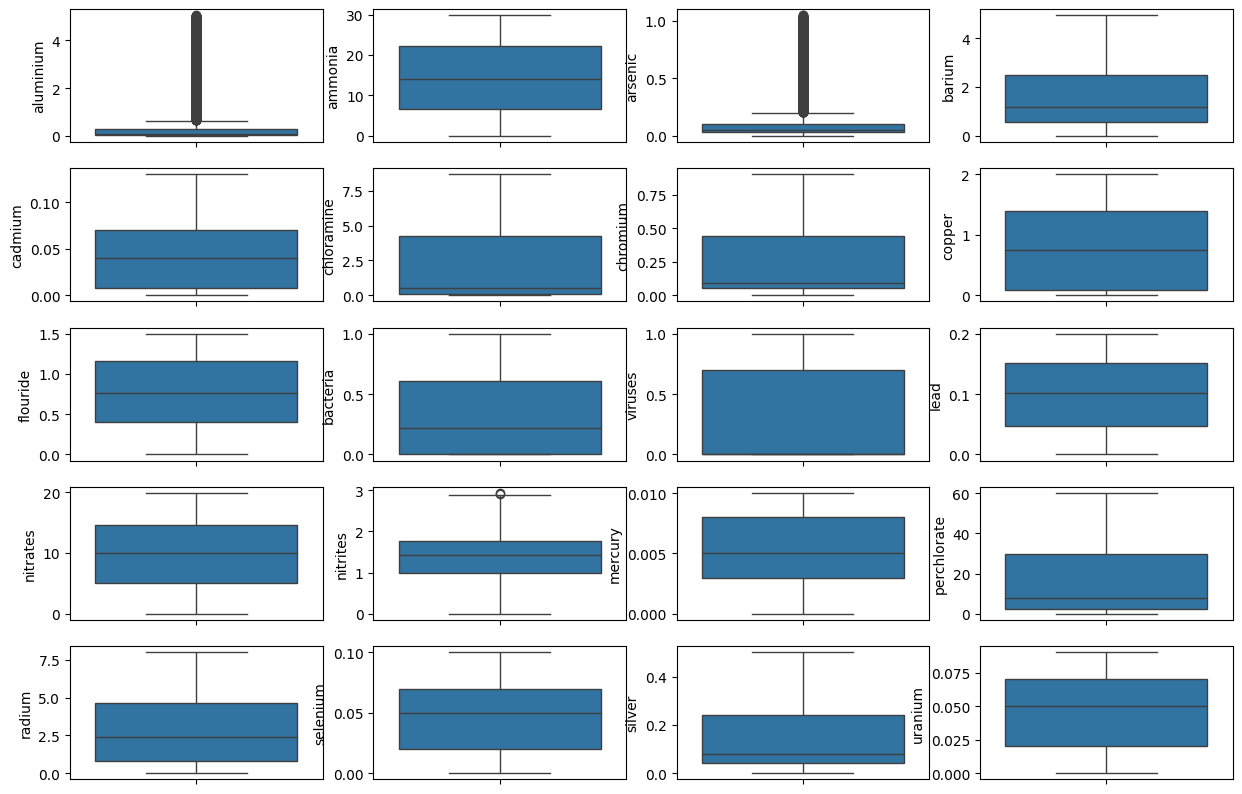

In [16]:
fig, ax = plt.subplots(5, 4, figsize=(15,10))  # Adjust the size as needed
index = 0
for col, values in df.items():
    if index < len(ax.flat):
        sns.boxplot(y=col, data=df, ax=ax.flat[index])
        index += 1
    else:
        break

### <a id='toc1_6_1_'></a>[***Observations:***](#toc0_)
- **We can observe that aluminium, arsenic, and nitrates have some outliers**

----

## <a id='toc1_7_'></a>[***Handling of Outliers***](#toc0_)

For handling outliers we have two techniques
- IQR method
- Z-score method

In [17]:
x= np.quantile(df['aluminium'],[0.25,0.75])
iqr = x[1]-x[0]
uw = x[1] + 1.5 * iqr
lw = x[0] - 1.5 * iqr

In [18]:
df['aluminium'] = np.where(df['aluminium']>uw,uw,(np.where(df['aluminium']<lw,lw,df['aluminium'])))


In [19]:
x= np.quantile(df['arsenic'],[0.25,0.75])
iqr = x[1]-x[0]
uw = x[1] + 1.5 * iqr
lw = x[0] - 1.5 * iqr

In [20]:
df['arsenic'] = np.where(df['arsenic']>uw,uw,(np.where(df['arsenic']<lw,lw,df['arsenic'])))

In [21]:
x= np.quantile(df['nitrites'],[0.25,0.75])
iqr = x[1]-x[0]
uw = x[1] + 1.5 * iqr
lw = x[0] - 1.5 * iqr

In [22]:
df['nitrites'] = np.where(df['nitrites']>uw,uw,(np.where(df['nitrites']<lw,lw,df['nitrites'])))

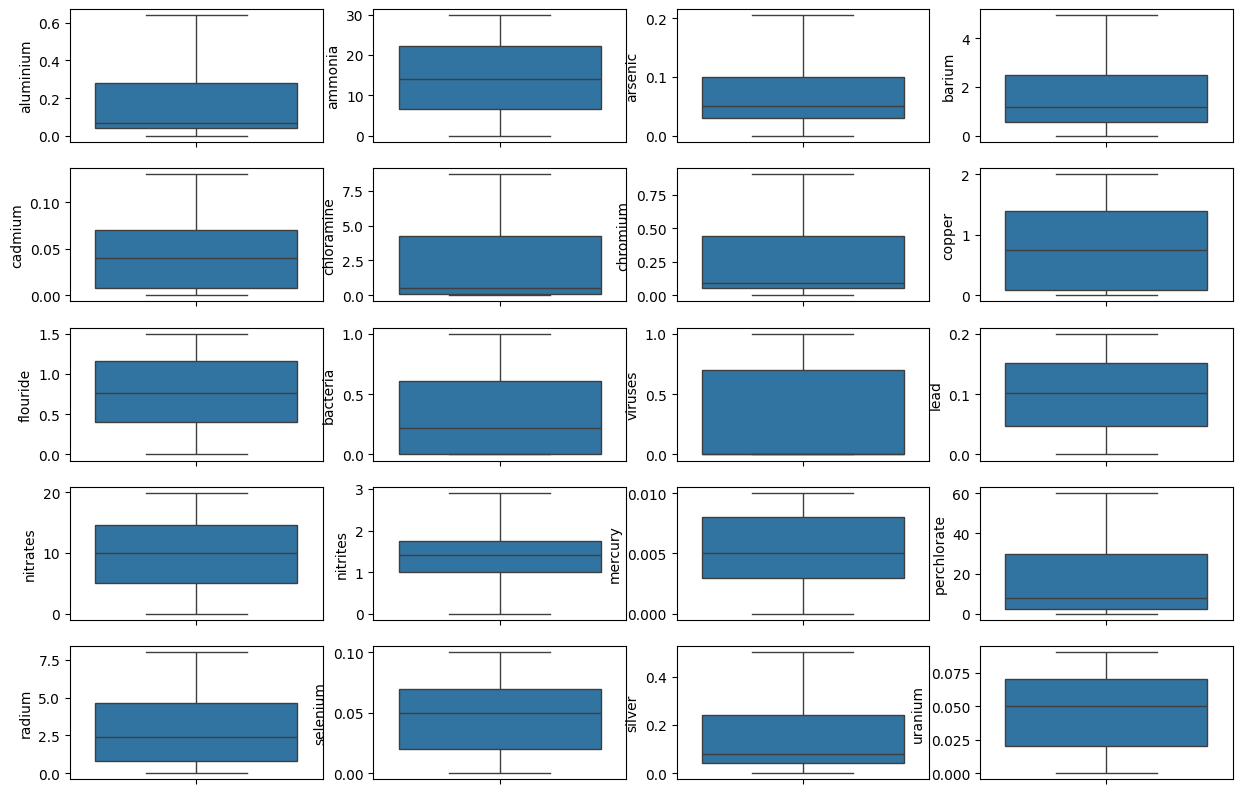

In [23]:
fig, ax = plt.subplots(5, 4, figsize=(15,10))  # Adjust the size as needed
index = 0
for col, values in df.items():
    if index < len(ax.flat):
        sns.boxplot(y=col, data=df, ax=ax.flat[index])
        index += 1
    else:
        break

outliers has been handled

In [24]:
df.columns


Index(['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine',
       'chromium', 'copper', 'flouride', 'bacteria', 'viruses', 'lead',
       'nitrates', 'nitrites', 'mercury', 'perchlorate', 'radium', 'selenium',
       'silver', 'uranium', 'potability'],
      dtype='object')

# <a id='toc2_'></a>[Data Visualizations](#toc0_)

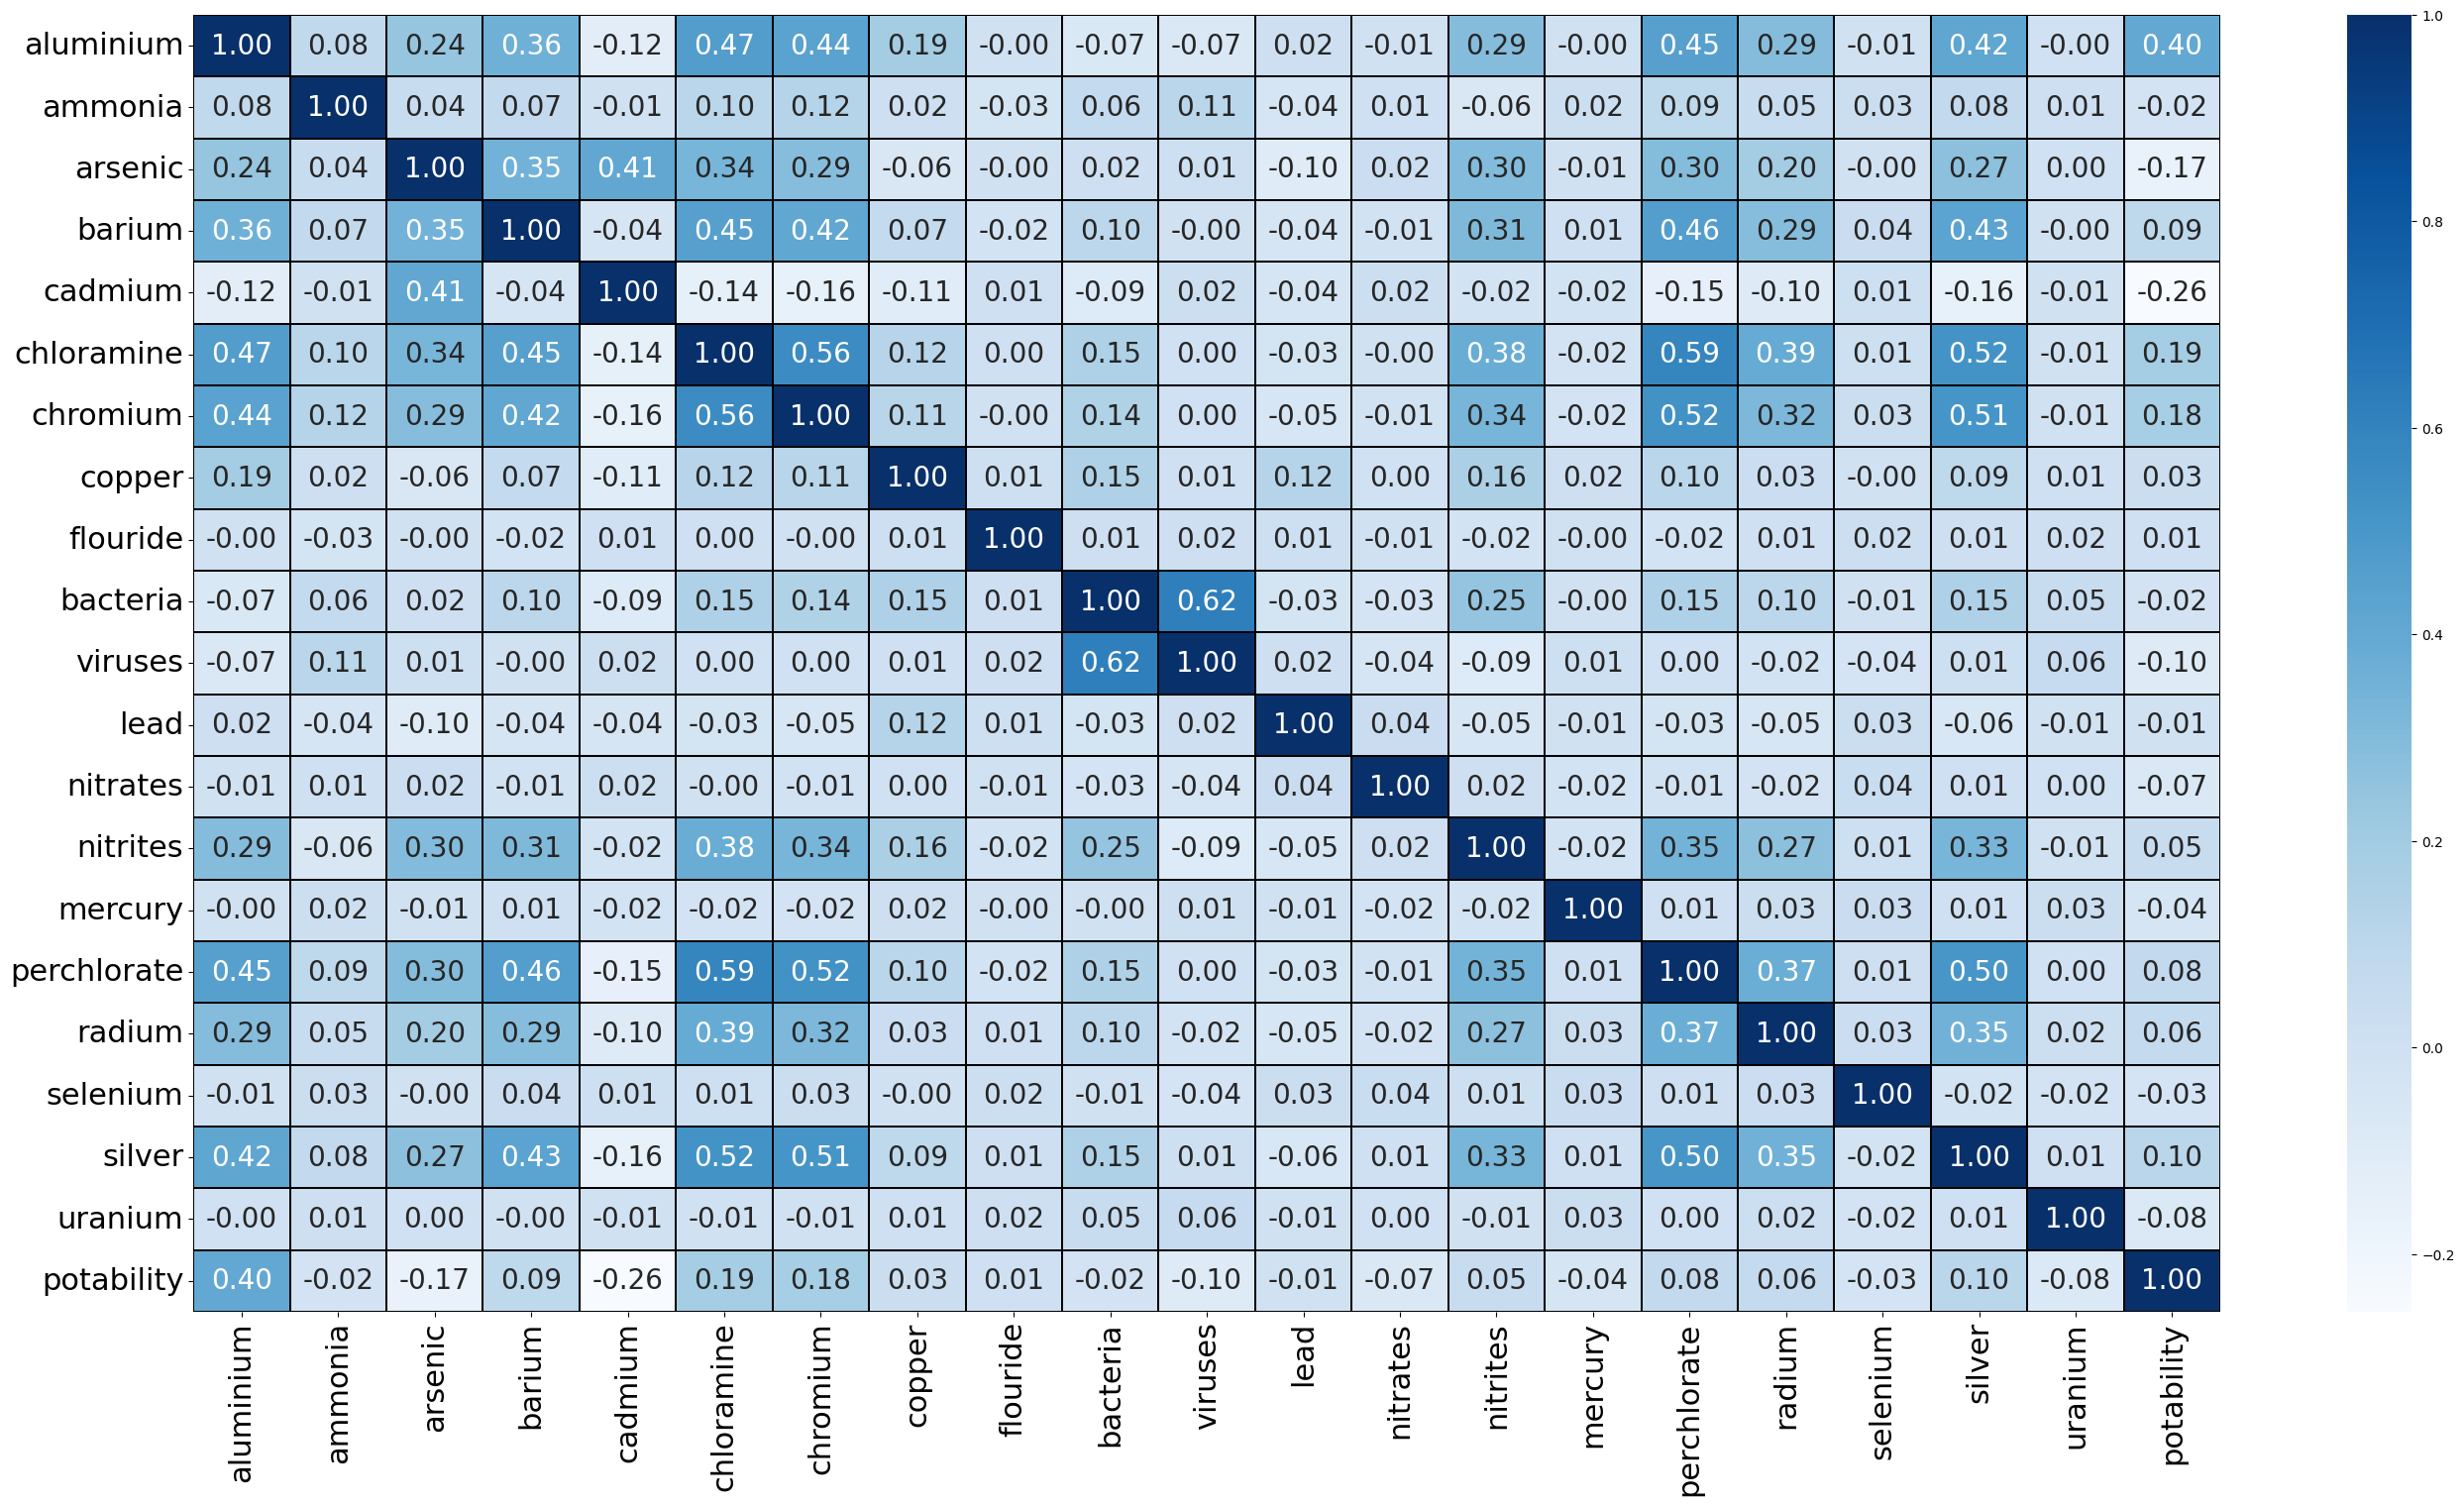

In [25]:
plt.figure(figsize = (33,17))
corr = df.corr()
sns.heatmap(corr, annot = True, cmap = 'Blues', linewidths = 0.01, linecolor = 'black',
            fmt = '0.2f', annot_kws = {'fontsize' : 20})
plt.yticks(fontsize = 22, rotation = 0)
plt.xticks(fontsize = 22, rotation = 90)
plt.show()

In [26]:
fig = px.pie(df,names="potability",hole = 0.4,template = "plotly_dark")
fig.show()

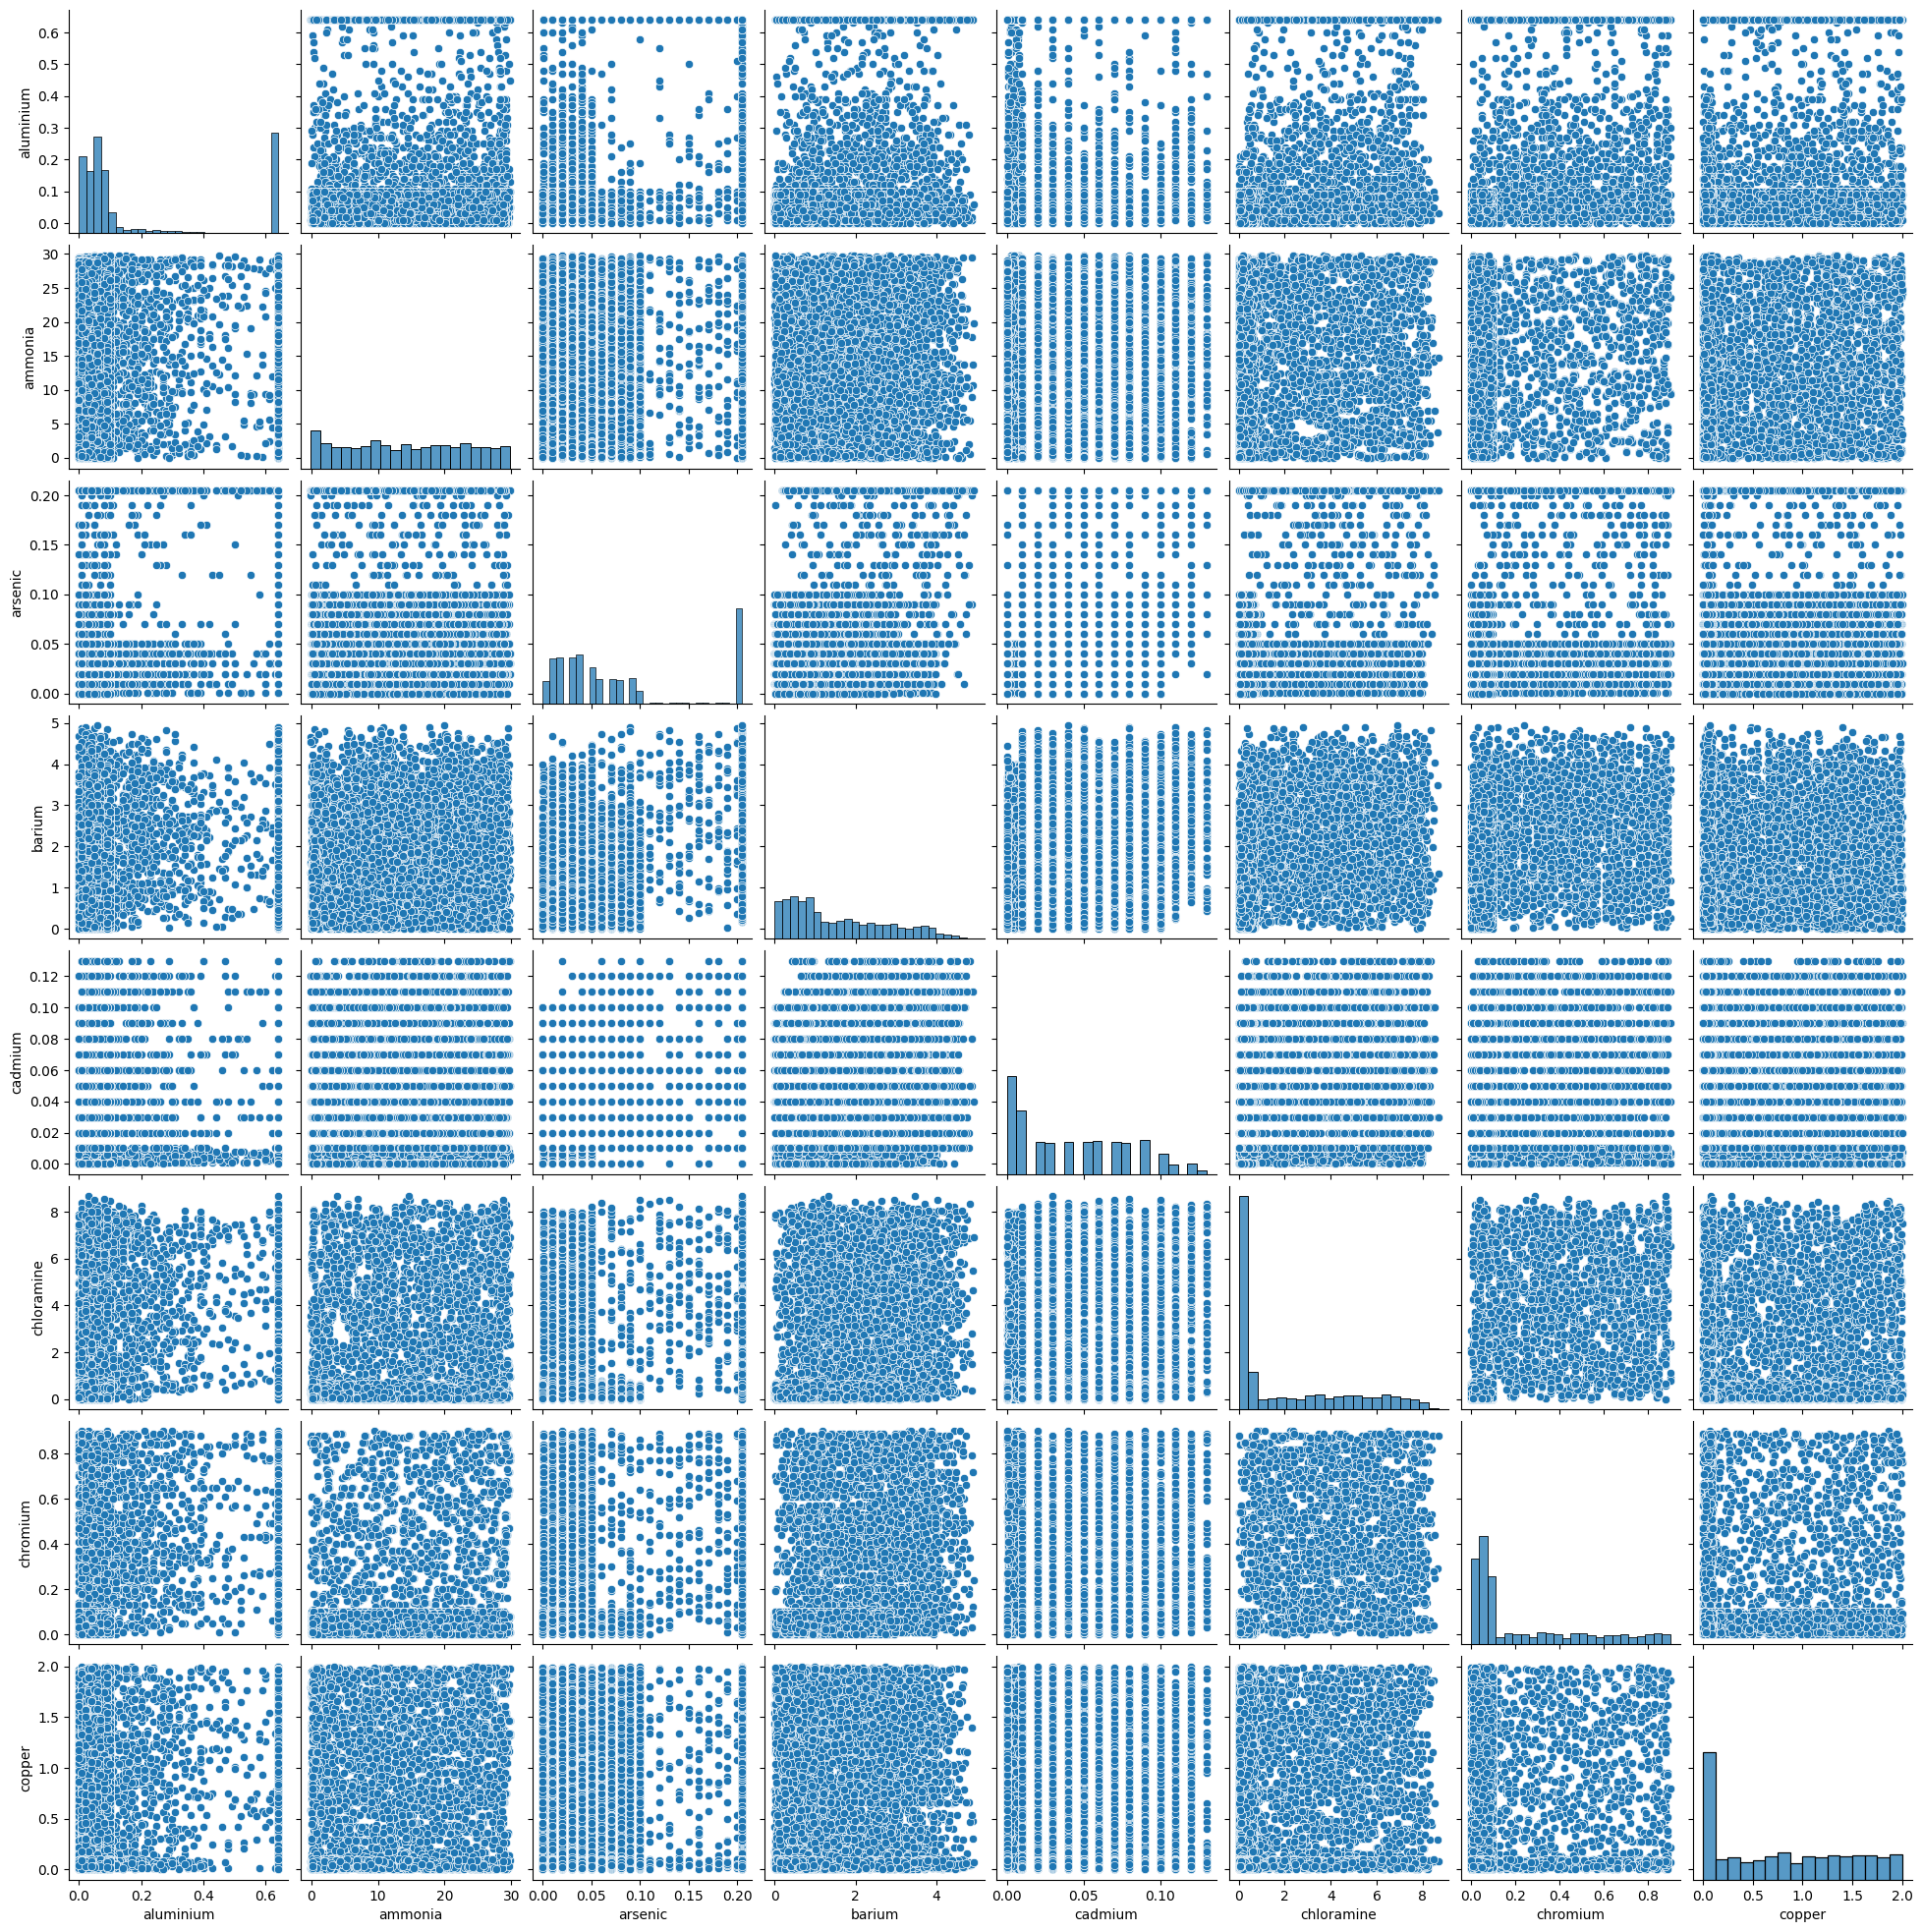

In [27]:
sns.pairplot(df[['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine', 'chromium', 'copper']])

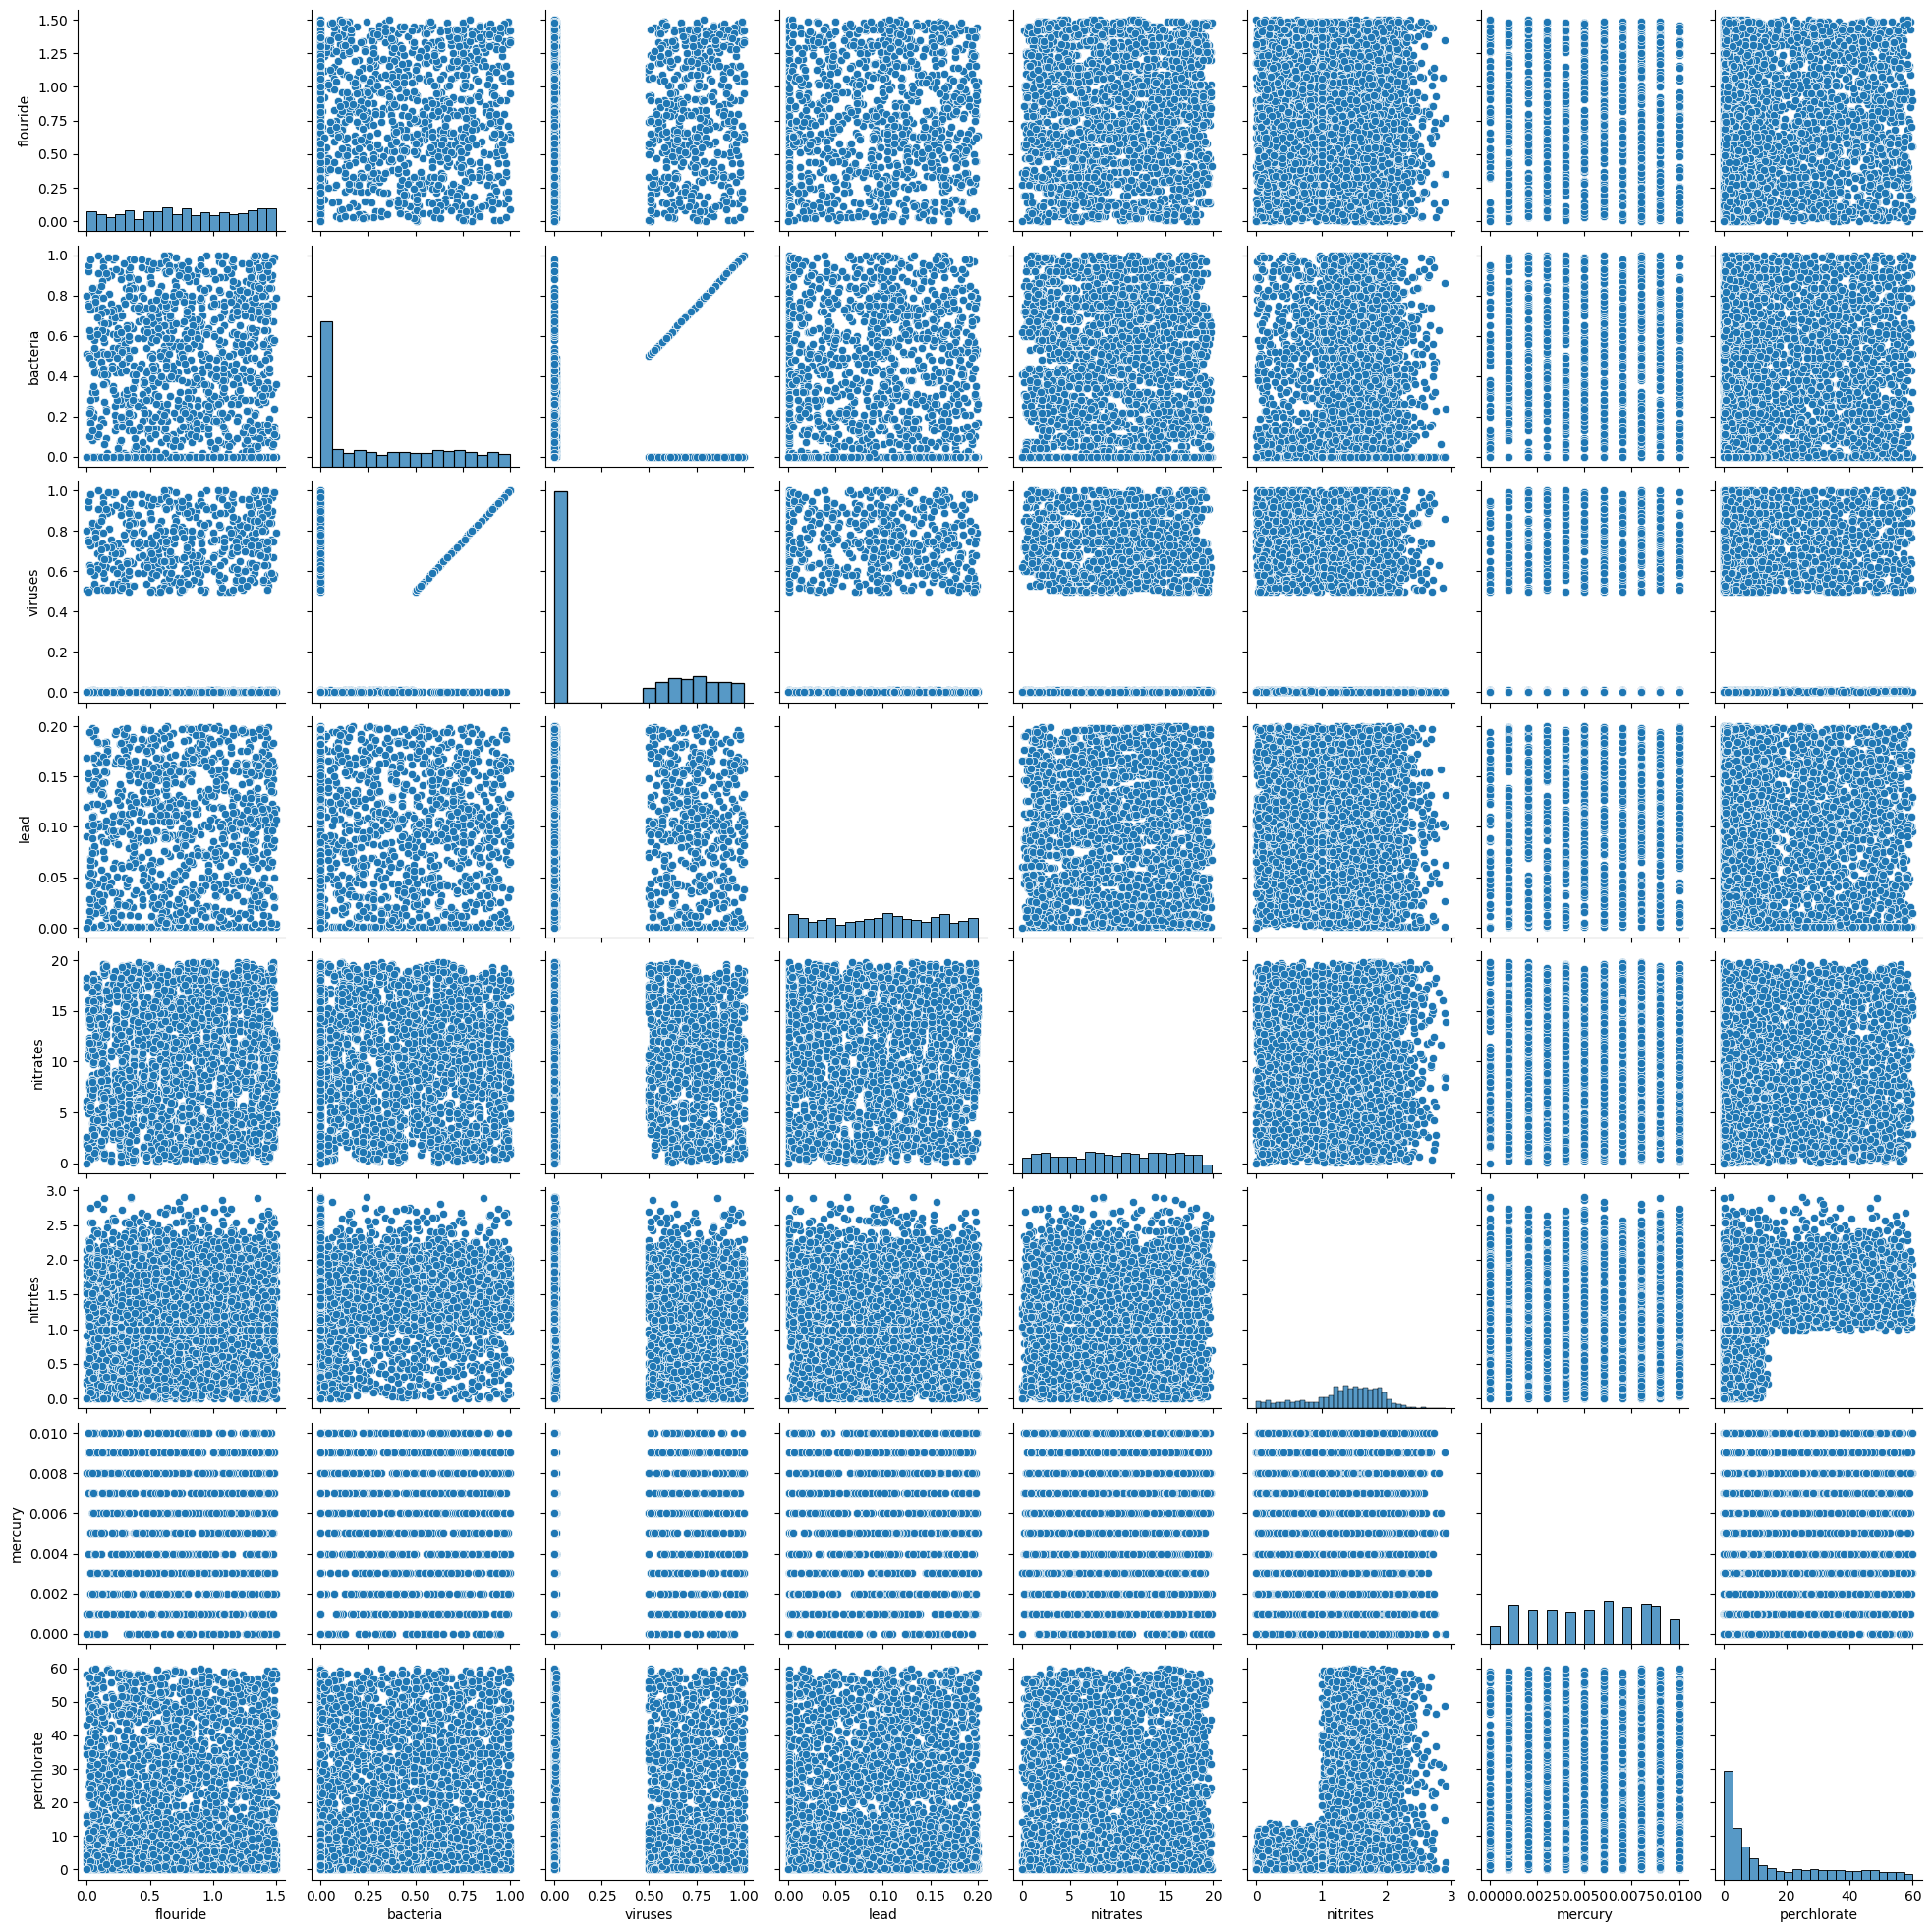

In [28]:
sns.pairplot(df[['flouride', 'bacteria', 'viruses', 'lead', 'nitrates', 'nitrites', 'mercury', 'perchlorate']])

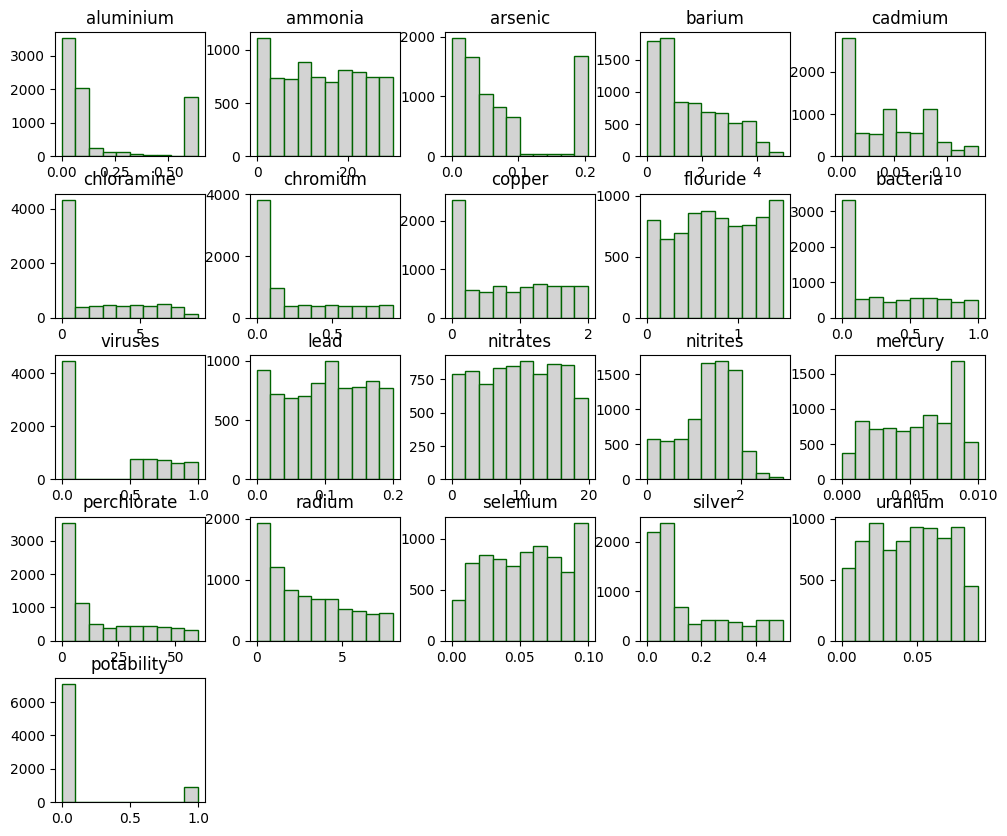

In [29]:
df.hist(grid = False, color ='lightgrey', edgecolor = 'darkgreen', figsize = (12,10));

In [30]:
fig = px.scatter(df,x = "radium",y="arsenic")
fig.show()

In [31]:
fig = px.scatter(df,x = "nitrates",y="chromium")
fig.show()

In [32]:
fig = px.scatter(df,x = "barium",y="copper")
fig.show()

In [35]:
fig = px.scatter(df,x = "nitrites",y="nitrates",color = "potability")
fig.show()

In [36]:
fig = px.scatter(df,x = "lead",y="chromium",color = "potability")
fig.show()

In [37]:
fig = px.scatter(df,x = "bacteria",y = "flouride",color = "potability")
fig.show()

In [38]:
fig = px.scatter(df,x = "chloramine",y = "viruses",color = "potability")
fig.show()

---
---

# <a id='toc3_'></a>[Pre Processing of Data](#toc0_)

In [39]:
x = df.drop("potability",axis=1)
y = df["potability"]

In [40]:
from imblearn.over_sampling import SMOTE
from collections import Counter
print(Counter(y))


Counter({0: 7084, 1: 912})


In [41]:
smote = SMOTE()
x_resampled, y_resampled = smote.fit_resample(x, y)


In [42]:
x_resampled.shape, y_resampled.shape

((14168, 20), (14168,))

In [43]:
print(Counter(y_resampled))

Counter({1: 7084, 0: 7084})


In [44]:
x.shape , y.shape

((7996, 20), (7996,))

In [45]:
x = x_resampled
y = y_resampled

In [46]:
fig = px.pie(y,names="potability",hole = 0.4,template = "plotly_dark")
fig.show()

In [47]:
df.to_csv('output_file.csv', index=False)

In [48]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state = 42)

In [49]:
x_train.shape, x_test.shape

((11334, 20), (2834, 20))

---

## <a id='toc3_1_'></a>[***Logistic Regression***](#toc0_)

---

In [50]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression()

In [51]:
model_lr.fit(x_train,y_train)

LogisticRegression()

In [52]:
pred_lr = model_lr.predict(x_test)

In [53]:
accuracy_score_lr = accuracy_score(y_test,pred_lr)
accuracy_score_lr*100

80.45165843330982

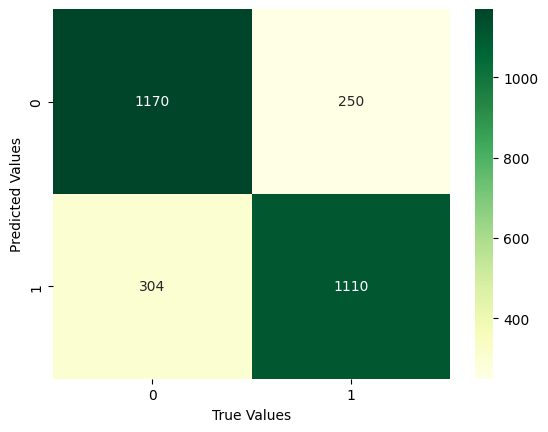

In [54]:
sns.heatmap((confusion_matrix(y_test,pred_lr)),annot=True,fmt='.5g',cmap="YlGn");
plt.xlabel('True Values')
plt.ylabel('Predicted Values');

In [55]:
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.79      0.82      0.81      1420
           1       0.82      0.79      0.80      1414

    accuracy                           0.80      2834
   macro avg       0.80      0.80      0.80      2834
weighted avg       0.80      0.80      0.80      2834



---
---

## <a id='toc3_2_'></a>[***Decision Tree Classifier***](#toc0_)

---

In [56]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(max_depth = 4)

In [57]:
for i in range(1,11):
    model_dt = DecisionTreeClassifier(max_depth=i)
    model_dt.fit(x_train,y_train)
    pred_dt = model_dt.predict(x_test)
    accuracy_score_dt = accuracy_score(y_test,pred_dt)
    print(i,accuracy_score_dt)

1 0.7872265349329569
2 0.8465067043048694
3 0.8465067043048694
4 0.8990825688073395
5 0.9234297812279464
6 0.9386026817219478
7 0.9442484121383204
8 0.952364149611856
9 0.9562455892731122
10 0.9594213126323218


In [58]:
model_dt.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=10)

In [59]:
pred_dt = model_dt.predict(x_test)

In [60]:
accuracy_score_dt = accuracy_score(y_test,pred_dt)
accuracy_score_dt*100

96.01270289343684

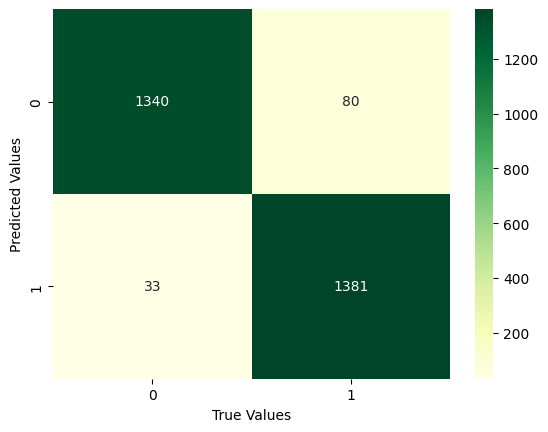

In [61]:
sns.heatmap((confusion_matrix(y_test,pred_dt)),annot=True,fmt='.5g',cmap="YlGn");
plt.xlabel('True Values')
plt.ylabel('Predicted Values');

In [62]:
print(classification_report(y_test, pred_dt))

              precision    recall  f1-score   support

           0       0.98      0.94      0.96      1420
           1       0.95      0.98      0.96      1414

    accuracy                           0.96      2834
   macro avg       0.96      0.96      0.96      2834
weighted avg       0.96      0.96      0.96      2834



---
---

## <a id='toc3_3_'></a>[***Random Forest Classifier***](#toc0_)

In [63]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier()

In [64]:
model_rf.fit(x_train,y_train)

RandomForestClassifier()

In [65]:
pred_rf = model_rf.predict(x_test)
print("Predicted: ",Counter(pred_rf))
print("Actual: ",Counter(y_test))

Predicted:  Counter({np.int64(1): 1447, np.int64(0): 1387})
Actual:  Counter({0: 1420, 1: 1414})


In [66]:
accuracy_score_rf = accuracy_score(y_test,pred_rf)
accuracy_score_rf*100

96.85956245589273

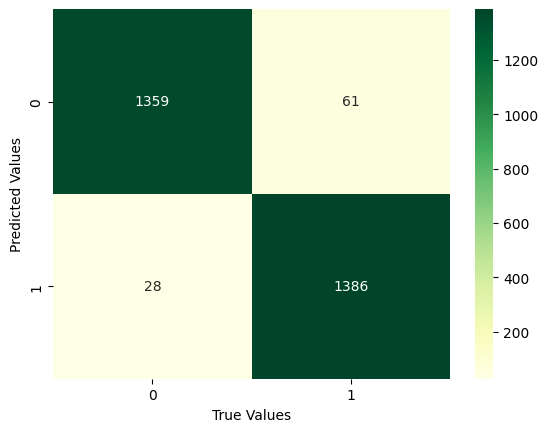

In [67]:
sns.heatmap((confusion_matrix(y_test,pred_rf)),annot=True,fmt='.5g',cmap="YlGn");
plt.xlabel('True Values')
plt.ylabel('Predicted Values');

In [68]:
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1420
           1       0.96      0.98      0.97      1414

    accuracy                           0.97      2834
   macro avg       0.97      0.97      0.97      2834
weighted avg       0.97      0.97      0.97      2834



---
---

## <a id='toc3_4_'></a>[***KNN --- K-Nearest-Neighbours***](#toc0_)

---

In [69]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier()

In [70]:
for i in range(4,11):
    model_knn = KNeighborsClassifier(n_neighbors=i)
    model_knn.fit(x_train,y_train)
    pred_knn = model_knn.predict(x_test)
    accuracy_score_knn = accuracy_score(y_test,pred_knn)
    print(i,accuracy_score_knn)

4 0.8729710656316161
5 0.8475652787579393
6 0.8542695836273818
7 0.8369795342272407
8 0.8436838390966831
9 0.8292166549047283
10 0.8327452364149612


- ***Lets take "4" for n_neighbors because it is giving 87% accuracy***

In [71]:
model_knn = KNeighborsClassifier(n_neighbors=4)
model_knn.fit(x_train,y_train)
pred_knn = model_knn.predict(x_test)
accuracy_score_knn = accuracy_score(y_test,pred_knn)
print(accuracy_score_knn*100)

87.2971065631616


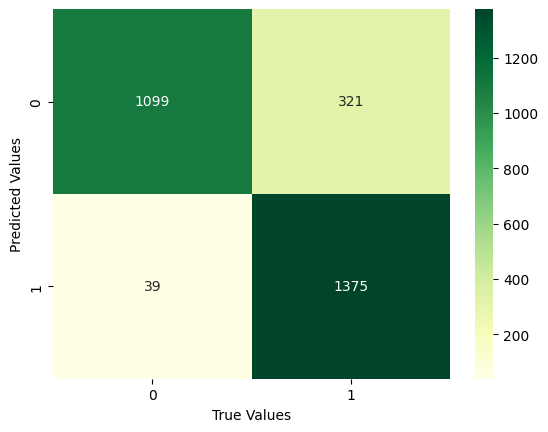

In [72]:
sns.heatmap((confusion_matrix(y_test,pred_knn)),annot=True,fmt='.5g',cmap="YlGn");
plt.xlabel('True Values')
plt.ylabel('Predicted Values');

In [73]:
print(classification_report(y_test, pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.77      0.86      1420
           1       0.81      0.97      0.88      1414

    accuracy                           0.87      2834
   macro avg       0.89      0.87      0.87      2834
weighted avg       0.89      0.87      0.87      2834



---
---

## <a id='toc3_5_'></a>[***Support Vector Machine***](#toc0_)
---

In [74]:
from sklearn.svm import SVC

model_svm = SVC(kernel="rbf")

In [75]:
model_svm.fit(x_train,y_train)

SVC()

In [76]:
pred_svm = model_svm.predict(x_test)

In [77]:
accuracy_score_svm = accuracy_score(y_test,pred_svm)
accuracy_score_svm*100

76.85250529287227

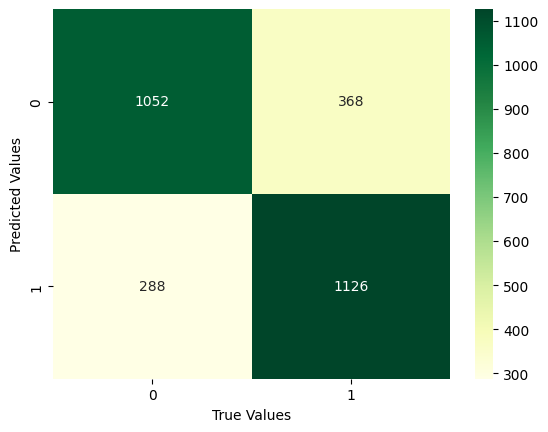

In [78]:
sns.heatmap((confusion_matrix(y_test,pred_svm)),annot=True,fmt='.5g',cmap="YlGn");
plt.xlabel('True Values')
plt.ylabel('Predicted Values');

In [79]:
print(classification_report(y_test, pred_svm))

              precision    recall  f1-score   support

           0       0.79      0.74      0.76      1420
           1       0.75      0.80      0.77      1414

    accuracy                           0.77      2834
   macro avg       0.77      0.77      0.77      2834
weighted avg       0.77      0.77      0.77      2834



---
---

In [91]:
from sklearn.naive_bayes import GaussianNB

model_gnb = GaussianNB()

In [92]:
model_gnb.fit(x_train,y_train)

GaussianNB()

In [93]:
pred_gnb = model_gnb.predict(x_test)

In [94]:
accuracy_score_gnb = accuracy_score(y_test,pred_gnb)
accuracy_score_gnb*100

80.41637261820748

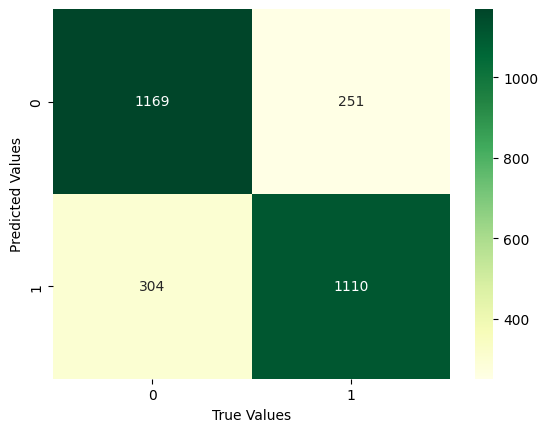

In [95]:
sns.heatmap((confusion_matrix(y_test,pred_gnb)),annot=True,fmt='.5g',cmap="YlGn");
plt.xlabel('True Values')
plt.ylabel('Predicted Values');

In [96]:
print(classification_report(y_test, pred_gnb))

              precision    recall  f1-score   support

           0       0.79      0.82      0.81      1420
           1       0.82      0.79      0.80      1414

    accuracy                           0.80      2834
   macro avg       0.80      0.80      0.80      2834
weighted avg       0.80      0.80      0.80      2834



---
---

# <a id='toc4_'></a>[Model Accuracy](#toc0_)

In [114]:
models = pd.DataFrame({
    "Model": ["Logistic Regression",
              "Decision Tree",
              "Random Forest",
              "KNN",
              "SVM"],





    "Accuracy Score" : [accuracy_score_lr*100,accuracy_score_dt*100,accuracy_score_rf*100,accuracy_score_knn*100,
                        accuracy_score_svm*100]

})

In [115]:
models

,Model,Accuracy Score
0,Logistic Regression,80.451658
1,Decision Tree,96.012703
2,Random Forest,96.859562
3,KNN,87.297107
4,SVM,76.852505


In [116]:
models.sort_values(by="Accuracy Score",ascending= False)

,Model,Accuracy Score
2,Random Forest,96.859562
1,Decision Tree,96.012703
3,KNN,87.297107
0,Logistic Regression,80.451658
4,SVM,76.852505


---

## <a id='toc4_1_'></a>[***Accuracy Chart***](#toc0_)

<Axes: xlabel='Accuracy Score', ylabel='Model'>

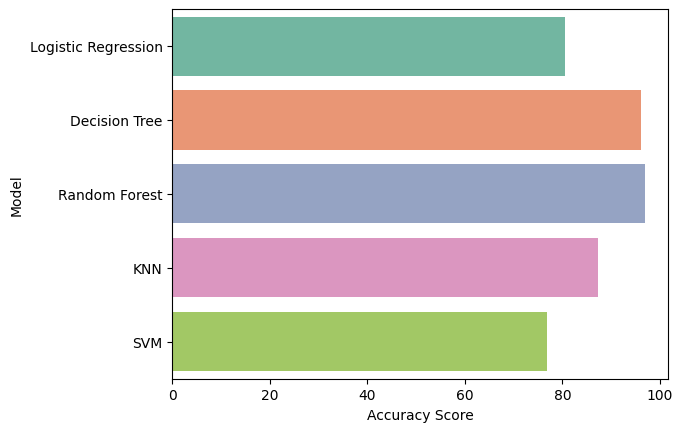

In [117]:
sns.barplot(x="Accuracy Score",y= "Model",data=models, palette='Set2')

### <a id='toc4_1_1_'></a>[***Random Forest Model is giving best accuracy score***](#toc0_)